In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

DATA_PATH = Path("../data/uber-data.csv")
FIGURES_DIR = Path("../figures")

df = pd.read_csv(DATA_PATH)

print("Dataset dimensions:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

Dataset dimensions: (1028136, 4)

Column names:
['Date/Time', 'Lat', 'Lon', 'Base']


,Date/Time,Lat,Lon,Base
0,9/1/2014 0:01:00,40.2201,-74.0021,B02512
1,9/1/2014 0:01:00,40.7500,-74.0027,B02512
2,9/1/2014 0:03:00,40.7559,-73.9864,B02512
3,9/1/2014 0:06:00,40.7450,-73.9889,B02512
4,9/1/2014 0:11:00,40.8145,-73.9444,B02512


In [24]:
# Examine the structure and quality of the dataset

print("DATASET INFORMATION")
df.info()

print("\nMISSING VALUES")
print(df.isna().sum())

print("\nDUPLICATED ROWS")
print(df.duplicated().sum())

print("\nNUMERICAL SUMMARY")
display(df[["Lat", "Lon"]].describe())

print("\nUBER BASE DISTRIBUTION")
display(df["Base"].value_counts())

DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 1028136 entries, 0 to 1028135
Data columns (total 4 columns):
 #   Column     Non-Null Count    Dtype  
---  ------     --------------    -----  
 0   Date/Time  1028136 non-null  str    
 1   Lat        1028136 non-null  float64
 2   Lon        1028136 non-null  float64
 3   Base       1028136 non-null  str    
dtypes: float64(2), str(2)
memory usage: 31.4 MB

MISSING VALUES
Date/Time    0
Lat          0
Lon          0
Base         0
dtype: int64

DUPLICATED ROWS
24037

NUMERICAL SUMMARY


,Lat,Lon
count,1.028136e+06,1.028136e+06
mean,4.073922e+01,-7.397182e+01
std,4.082861e-02,5.831413e-02
min,3.998970e+01,-7.477360e+01
25%,4.072040e+01,-7.399620e+01
50%,4.074180e+01,-7.398310e+01
75%,4.076120e+01,-7.396280e+01
max,4.134760e+01,-7.271630e+01



UBER BASE DISTRIBUTION


Base
B02617    377695
B02598    240600
B02682    197138
B02764    178333
B02512     34370
Name: count, dtype: int64

In [25]:
# Convert dates and examine geographical validity

df["Date/Time"] = pd.to_datetime(
    df["Date/Time"],
    format="%m/%d/%Y %H:%M:%S",
    errors="coerce"
)

print("INVALID DATES")
print(df["Date/Time"].isna().sum())

print("\nDATE RANGE")
print("First observation:", df["Date/Time"].min())
print("Last observation:", df["Date/Time"].max())

print("\nINVALID GEOGRAPHICAL COORDINATES")
invalid_coordinates = (
    ~df["Lat"].between(-90, 90)
    | ~df["Lon"].between(-180, 180)
)

print(invalid_coordinates.sum())

print("\nCOORDINATE RANGES")
print("Latitude:", df["Lat"].min(), "to", df["Lat"].max())
print("Longitude:", df["Lon"].min(), "to", df["Lon"].max())

INVALID DATES
0

DATE RANGE
First observation: 2014-09-01 00:00:00
Last observation: 2014-09-30 22:59:00

INVALID GEOGRAPHICAL COORDINATES
0

COORDINATE RANGES
Latitude: 39.9897 to 41.3476
Longitude: -74.7736 to -72.7163


In [26]:
# Extract temporal information

df["Date"] = df["Date/Time"].dt.date
df["Hour"] = df["Date/Time"].dt.hour
df["DayOfWeek"] = df["Date/Time"].dt.day_name()

print("TEMPORAL VARIABLES")
display(df.head())

print("\nNUMBER OF DATES")
print(df["Date"].nunique())

print("\nHOURLY DISTRIBUTION")
display(df["Hour"].value_counts().sort_index())

print("\nDAILY DISTRIBUTION")
display(df.groupby("Date").size())


TEMPORAL VARIABLES


,Date/Time,Lat,Lon,Base,Date,Hour,DayOfWeek
0,2014-09-01 00:01:00,40.2201,-74.0021,B02512,2014-09-01,0,Monday
1,2014-09-01 00:01:00,40.7500,-74.0027,B02512,2014-09-01,0,Monday
2,2014-09-01 00:03:00,40.7559,-73.9864,B02512,2014-09-01,0,Monday
3,2014-09-01 00:06:00,40.7450,-73.9889,B02512,2014-09-01,0,Monday
4,2014-09-01 00:11:00,40.8145,-73.9444,B02512,2014-09-01,0,Monday



NUMBER OF DATES
30

HOURLY DISTRIBUTION


Hour
0     24133
1     16107
2     10702
3     10789
4     12675
5     20262
6     33307
7     43314
8     44477
9     38542
10    37634
11    38821
12    39193
13    45042
14    52643
15    61219
16    68224
17    73373
18    75040
19    69660
20    63988
21    60606
22    51817
23    36568
Name: count, dtype: int64


DAILY DISTRIBUTION


Date
2014-09-01    19961
2014-09-02    28831
2014-09-03    32631
2014-09-04    38360
2014-09-05    42319
2014-09-06    40520
2014-09-07    30134
2014-09-08    30360
2014-09-09    34560
2014-09-10    35910
2014-09-11    36439
2014-09-12    39540
2014-09-13    43205
2014-09-14    28122
2014-09-15    29454
2014-09-16    36092
2014-09-17    35531
2014-09-18    40274
2014-09-19    41017
2014-09-20    38864
2014-09-21    28620
2014-09-22    28312
2014-09-23    30316
2014-09-24    31301
2014-09-25    38203
2014-09-26    37504
2014-09-27    39468
2014-09-28    29656
2014-09-29    29201
2014-09-30    33431
dtype: int64

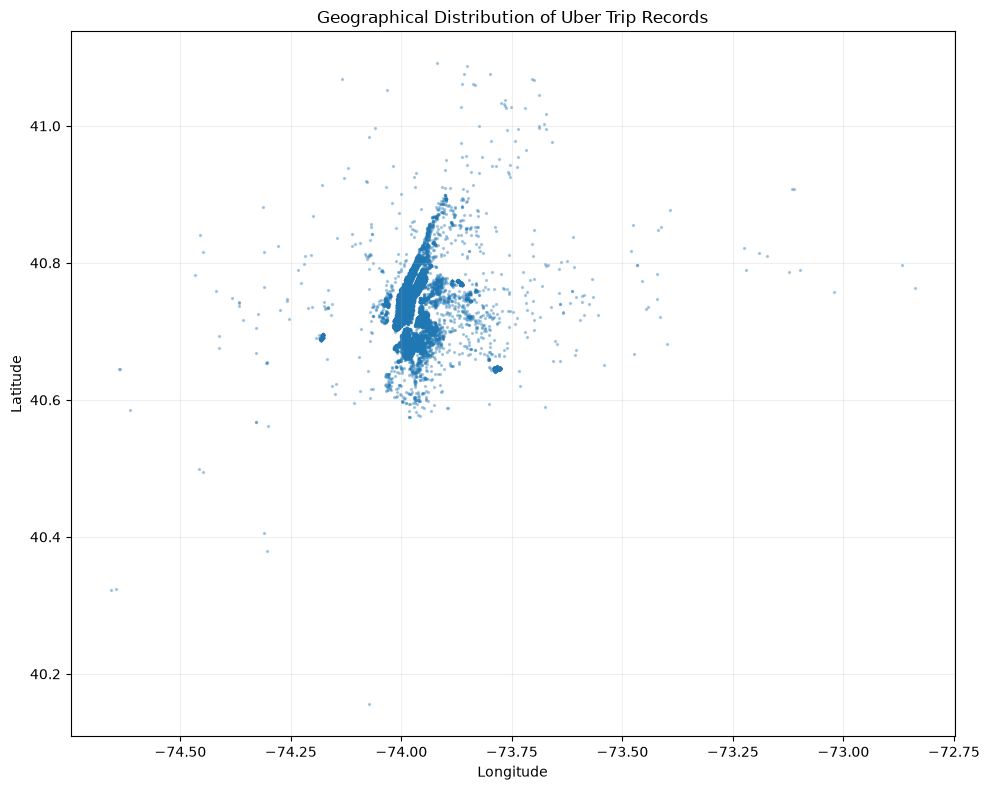

In [27]:
# Visualize the geographical distribution of Uber trips

sample = df.sample(n=20000, random_state=42)

plt.figure(figsize=(10, 8))

plt.scatter(
    sample["Lon"],
    sample["Lat"],
    s=2,
    alpha=0.3
)

plt.title("Geographical Distribution of Uber Trip Records")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(alpha=0.2)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "01_geographical_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [28]:
# Examine the geographical concentration of trip records

coordinate_quantiles = df[["Lat", "Lon"]].quantile(
    [0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
)

print("COORDINATE QUANTILES")
display(coordinate_quantiles)

print("\nOBSERVATIONS WITHIN CENTRAL COORDINATE RANGES")

lat_min, lat_max = df["Lat"].quantile([0.01, 0.99])
lon_min, lon_max = df["Lon"].quantile([0.01, 0.99])

central_region = (
    df["Lat"].between(lat_min, lat_max)
    & df["Lon"].between(lon_min, lon_max)
)

print("Observations:", central_region.sum())
print("Percentage:", round(central_region.mean() * 100, 2))

COORDINATE QUANTILES


,Lat,Lon
0.01,40.6394,-74.115565
0.05,40.6703,-74.010400
0.25,40.7204,-73.996200
0.50,40.7418,-73.983100
0.75,40.7612,-73.962800
0.95,40.7889,-73.865300
0.99,40.8540,-73.776800



OBSERVATIONS WITHIN CENTRAL COORDINATE RANGES
Observations: 991013
Percentage: 96.39
